In [1]:

import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("MACHINEGUARD ML PROJECT")
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries are working!")


MACHINEGUARD ML PROJECT
Python: 3.14.7
Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1
All libraries are working!


In [2]:

from pathlib import Path
import pandas as pd

# Находим главную папку проекта
project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Указываем путь к датасету
file_path = project_dir / "data" / "raw" / "ai4i2020.csv"


# Загружаем данные
df = pd.read_csv(file_path)

# Показываем первые 5 строк
display(df.head()) 


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:

print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])
print("Размер таблицы:", df.shape)


Количество строк: 10000
Количество столбцов: 14
Размер таблицы: (10000, 14)


In [4]:

# Информация о столбцах
print("=== ИНФОРМАЦИЯ О ДАННЫХ ===")
df.info()

# Проверка пропущенных значений
print("\n=== ПРОПУЩЕННЫЕ ЗНАЧЕНИЯ ===")
print(df.isnull().sum())

# Проверка дубликатов
print("\n=== ДУБЛИКАТЫ ===")
print("Количество дубликатов:", df.duplicated().sum())


=== ИНФОРМАЦИЯ О ДАННЫХ ===
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: flo

In [5]:

missing_values = df.isnull().sum().sum()

print("Всего пропущенных значений:", missing_values)
print("Всего дубликатов:", df.duplicated().sum())


Всего пропущенных значений: 0
Всего дубликатов: 0


In [6]:

# Основная статистика датасета
print("=== СТАТИСТИКА MACHINEGUARD ===")

display(df.describe())


=== СТАТИСТИКА MACHINEGUARD ===


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### Initial Data Analysis — Findings

The dataset contains 10,000 records and 14 columns. No missing values or duplicate rows were detected.

The average air temperature is approximately 300.00 K, while the average process temperature is 310.01 K. This indicates that the process temperature is approximately 10 K higher on average.

Air temperature ranges from 295.3 K to 304.5 K, while process temperature ranges from 305.7 K to 313.8 K.

These observations provide an initial understanding of the operating conditions. Further analysis is required to determine whether temperature is associated with machine failures.

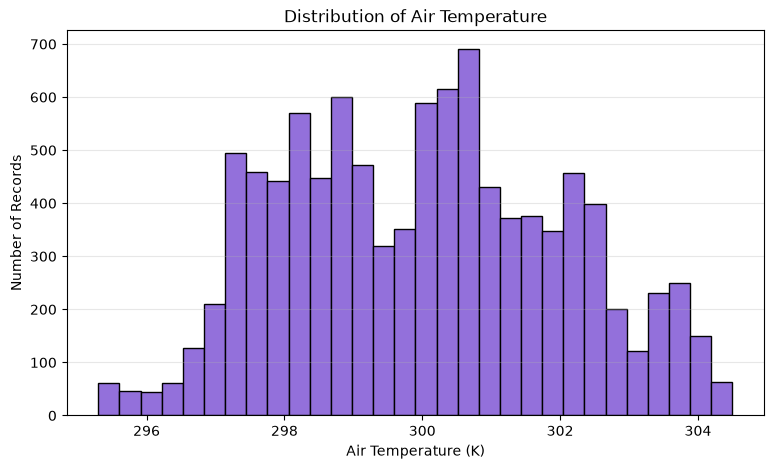

In [7]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    df["Air temperature [K]"],
    bins=30,
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Distribution of Air Temperature")
plt.xlabel("Air Temperature (K)")
plt.ylabel("Number of Records")

plt.grid(axis="y", alpha=0.3)
plt.show()


### Air Temperature Distribution — Analysis

The histogram shows that air temperature ranges from approximately 295.3 K to 304.5 K.

Most observations are concentrated between 297 K and 303 K. The distribution has several peaks, with the highest frequency occurring around 300–301 K.

The distribution is not perfectly symmetric, suggesting that some temperature ranges occur more frequently than others.

Further analysis is required to determine whether air temperature is associated with machine failures.

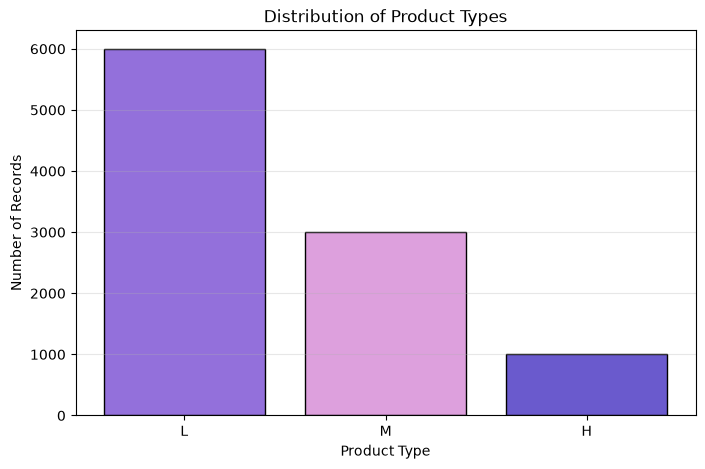

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


In [8]:

import matplotlib.pyplot as plt

# Подсчитываем количество каждого типа
type_counts = df["Type"].value_counts()

# Создаём график
plt.figure(figsize=(8, 5))

plt.bar(
    type_counts.index,
    type_counts.values,
    color=["mediumpurple", "plum", "slateblue"],
    edgecolor="black"
)

plt.title("Distribution of Product Types")
plt.xlabel("Product Type")
plt.ylabel("Number of Records")

plt.grid(axis="y", alpha=0.3)
plt.show()

# Показываем точные значения
print(type_counts)


### Product Type Distribution — Analysis

The dataset contains three product quality categories: Low (L), Medium (M), and High (H).

Low-quality products represent the largest group, with 6,000 records (60%). Medium-quality products account for 2,997 records (29.97%), while high-quality products represent 1,003 records (10.03%).

The distribution is uneven, with low-quality products appearing most frequently.

Further analysis is needed to determine whether product type is associated with machine failure.

## Data Dictionary

The AI4I 2020 Predictive Maintenance dataset contains 10,000 records and 14 columns. The following table describes each column and its role in the project.

| Feature | Description |
|---|---|
| UDI | Unique identifier of each record. |
| Product ID | Unique product identifier containing a quality category and serial number. |
| Type | Product quality category: L (Low), M (Medium), or H (High). |
| Air temperature [K] | Air temperature measured in Kelvin. |
| Process temperature [K] | Process temperature measured in Kelvin. |
| Rotational speed [rpm] | Rotational speed of the machine in revolutions per minute. |
| Torque [Nm] | Torque generated during machine operation, measured in Newton-metres. |
| Tool wear [min] | Accumulated tool wear measured in minutes. |
| Machine failure | Binary target variable: 0 indicates no failure, 1 indicates failure. |
| TWF | Tool Wear Failure indicator. |
| HDF | Heat Dissipation Failure indicator. |
| PWF | Power Failure indicator. |
| OSF | Overstrain Failure indicator. |
| RNF | Random Failure indicator. |

### Feature Roles

**Target variable:** Machine failure.

**Potential input features:** Type, Air temperature, Process temperature, Rotational speed, Torque, and Tool wear.

**Identifiers:** UDI and Product ID should not be used directly as numerical predictors.

**Failure indicators:** TWF, HDF, PWF, OSF, and RNF describe specific failure types and must be excluded from the input features when predicting Machine failure to prevent target leakage.

## Dataset Selection and Justification

**Project Title:** MACHINEGUARD: Predictive Maintenance Using Machine Learning

**Dataset:** AI4I 2020 Predictive Maintenance Dataset

**Source:** UCI Machine Learning Repository

**Dataset URL:** https://archive.ics.uci.edu/dataset/601/ai4i%2B2020%2Bpredictive%2Bmaintenance%2Bdataset

### Project Overview

MACHINEGUARD is a machine learning project focused on predicting industrial equipment failures using operational data.

The main objective is to investigate how machine operating conditions are associated with equipment failures and develop models capable of identifying potential failure risks.

### Reasons for Dataset Selection

The AI4I 2020 dataset was selected for the following reasons:

1. **Open Accessibility:** The dataset is publicly available through the UCI Machine Learning Repository.

2. **Suitable Size:** The dataset contains 10,000 records and 14 columns, making it suitable for analysis on a standard personal computer.

3. **Relevant Features:** The dataset includes temperature, rotational speed, torque, tool wear, and product quality categories.

4. **Classification Task:** The Machine failure column allows the development of binary classification models.

5. **Machine Learning Applications:** The dataset supports exploratory data analysis, preprocessing, model evaluation, and feature importance analysis.

### Dataset Limitations

The dataset is synthetic and does not represent direct measurements from a real industrial facility.

It contains no missing values in its original form. Additional experiments may be required to investigate preprocessing methods for incomplete data.

The dataset also does not contain a suitable corpus of Russian or Kyrgyz texts for text classification. Therefore, a separate text dataset will be required for Practical Work 6.

### Expected Outcome

The project aims to develop and compare machine learning models, evaluate their predictive performance, and explain which operating conditions contribute most strongly to model predictions.